In [28]:
!pip install kagglehub

In [29]:
import kagglehub
path = kagglehub.dataset_download('waqi786/usa-rainfall-prediction-dataset-2024-2025')


Using Colab cache for faster access to the 'usa-rainfall-prediction-dataset-2024-2025' dataset.


In [30]:
import pandas as pd

data = pd.read_csv(path + "/usa_rain_prediction_dataset_2024_2025.csv")
data.head()

,Date,Location,Temperature,Humidity,Wind Speed,Precipitation,Cloud Cover,Pressure,Rain Tomorrow
0,2024-01-01,New York,87.524795,75.655455,28.379506,0.000000,69.617966,1026.030278,0
1,2024-01-02,New York,83.259325,28.712617,12.436433,0.526995,41.606048,995.962065,0
2,2024-01-03,New York,80.943050,64.740043,14.184831,0.916884,77.364763,980.796739,1
3,2024-01-04,New York,78.097552,59.738984,19.444029,0.094134,52.541196,979.012163,0
4,2024-01-05,New York,37.059963,34.766784,3.689661,1.361272,85.584000,1031.790859,0


In [31]:
print(data.shape)
data['Precipitation'].describe()
data.info()

(73100, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73100 entries, 0 to 73099
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           73100 non-null  object 
 1   Location       73100 non-null  object 
 2   Temperature    73100 non-null  float64
 3   Humidity       73100 non-null  float64
 4   Wind Speed     73100 non-null  float64
 5   Precipitation  73100 non-null  float64
 6   Cloud Cover    73100 non-null  float64
 7   Pressure       73100 non-null  float64
 8   Rain Tomorrow  73100 non-null  int64  
dtypes: float64(6), int64(1), object(2)
memory usage: 5.0+ MB


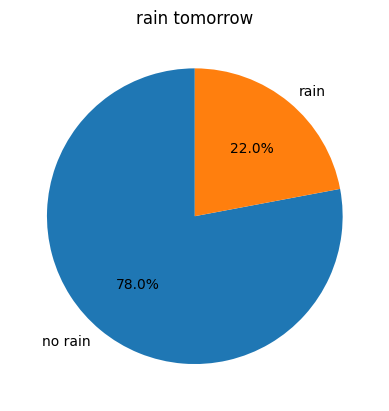

In [34]:
import matplotlib.pyplot as plt
rain_ = data['Rain Tomorrow'].value_counts().sort_index()
plt.pie(
    rain_ ,
    labels=['no rain','rain'],
    autopct='%1.1f%%',
    startangle=90
)
plt.title("rain tomorrow")
plt.show()


In [35]:
data = data.drop('Date', axis=1)
data = data.drop('Location', axis=1)

In [36]:

data = pd.get_dummies(data , drop_first=True)


In [37]:
print(data.columns.tolist())

['Temperature', 'Humidity', 'Wind Speed', 'Precipitation', 'Cloud Cover', 'Pressure', 'Rain Tomorrow']


In [38]:
data.head()

,Temperature,Humidity,Wind Speed,Precipitation,Cloud Cover,Pressure,Rain Tomorrow
0,87.524795,75.655455,28.379506,0.000000,69.617966,1026.030278,0
1,83.259325,28.712617,12.436433,0.526995,41.606048,995.962065,0
2,80.943050,64.740043,14.184831,0.916884,77.364763,980.796739,1
3,78.097552,59.738984,19.444029,0.094134,52.541196,979.012163,0
4,37.059963,34.766784,3.689661,1.361272,85.584000,1031.790859,0


In [39]:
from sklearn.model_selection import train_test_split
X= data.drop('Rain Tomorrow' , axis=1)
y = data['Rain Tomorrow']
x_train , x_test ,y_train , y_test = train_test_split(X , y , test_size=0.2 , random_state=21)

In [40]:
from sklearn.preprocessing import MinMaxScaler
scaler =  MinMaxScaler()
x_train =scaler.fit_transform(x_train)

In [41]:
x_test  = scaler.transform(x_test)

In [42]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()

In [43]:
model.fit(x_train,y_train)

LogisticRegression()

In [44]:
prediction = model.predict(x_test)
print(prediction[:5])
print(y_test[:5].values)


[0 1 0 0 0]
[0 0 0 0 0]


In [45]:
from sklearn.metrics import accuracy_score
accuracy=accuracy_score(y_test,prediction)

print(accuracy)


0.9057455540355677


In [46]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test,prediction)
print(cm)

[[10975   423]
 [  955  2267]]


In [47]:
from sklearn.metrics import classification_report
print(classification_report(y_test,prediction))

              precision    recall  f1-score   support

           0       0.92      0.96      0.94     11398
           1       0.84      0.70      0.77      3222

    accuracy                           0.91     14620
   macro avg       0.88      0.83      0.85     14620
weighted avg       0.90      0.91      0.90     14620

